In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

In [2]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'development', 'modeling')
pth_ref = os.path.join(pth_data, 'ref', 'AnimalTFDBv4')
pth_fig = os.path.join(pth, 'figures', 'development', 'regulation')
pth_out = os.path.join(pth_data, 'results')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'spectrum.h5ad'))
adata

AnnData object with n_obs × n_vars = 6405 × 14985
    obs: 'sample', 'celltype', 'source', 't_orig', 'early', 'late', 'spectrum', 't', 'seg', 'edge', 'milestones'
    uns: 'celltype_colors', 'graph', 'milestones_colors', 'pseudotime_list', 'seg_colors'
    obsm: 'X_R', 'X_pca', 'X_spectrum', 'X_umap', 'X_umap_traj'

In [4]:
# transcription factors
fn = os.path.join(pth_ref, 'Mus_musculus_TF')
tf = pd.read_csv(fn, sep = '\t').Symbol
tf = tf.loc[tf.isin(adata.var_names)].values

In [5]:
# X: TF expression, source
src = adata.obs.source.copy()
X = adata[:, tf].X.toarray()
X = StandardScaler().fit_transform(X)
src = pd.get_dummies(src).values.astype(float)
X = np.concatenate((X, src), axis = 1)

# y: pseudotime (per source)
y = adata.obs.t_orig.values.reshape(-1, 1)
y = StandardScaler().fit_transform(y).flatten()

# linear regression (y ~ X)
reg = LinearRegression(fit_intercept = False).fit(X, y)

# TF coefficients (beta)
beta = pd.Series(reg.coef_[:-src.shape[1]], index = tf)
beta = beta.sort_values(ascending = False); beta.name = 'coef'
beta.to_csv(os.path.join(pth_out, 'reg_coef.csv')); beta

Prrx1     0.125737
Dlx2      0.069751
Alx4      0.068982
Dlx1      0.056616
Meox1     0.052656
            ...   
T        -0.060460
En1      -0.077821
Otx2     -0.081503
Ybx1     -0.105955
Pou5f1   -0.141178
Name: coef, Length: 1289, dtype: float64

In [6]:
cmap_dict = {
    'Pou5f1' : 'Purples',
    'Prrx1'  : 'Greens'}

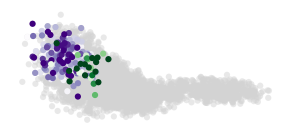

In [7]:
geo = 'GSE162534'
vlim = {'Pou5f1' : [3.85, 'p92'], 'Prrx1' : [.8, 'p50']}
adata_plt = adata[adata.obs.source == geo].copy()

fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
sc.pl.embedding(adata, 'X_spectrum', size = 80, alpha = .5,
                frameon = False, show = False, ax = ax)
for g, (vmin, vmax) in vlim.items():
    sc.pl.embedding(adata_plt[adata_plt[:, g].X.toarray() > vmin],
                    'X_spectrum', size = 80, color = g,
                    cmap = cmap_dict[g], vmin = vmin,
                    vmax = vmax, colorbar_loc = None,
                    frameon = False, show = False, ax = ax)
ax.set_title('')
fn = os.path.join(pth_fig, f'{geo}.pdf')
plt.savefig(fn, bbox_inches = 'tight')

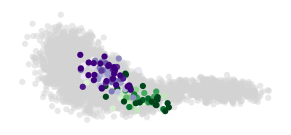

In [8]:
geo = 'GSE229103'
vlim = {'Prrx1' : [.5, 'p70'], 'Pou5f1' : [.7, 'p75']}
adata_plt = adata[adata.obs.source == geo].copy()

fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
sc.pl.embedding(adata, 'X_spectrum', size = 80, alpha = .5,
                frameon = False, show = False, ax = ax)
for g, (vmin, vmax) in vlim.items():
    sc.pl.embedding(adata_plt[adata_plt[:, g].X.toarray() > vmin],
                    'X_spectrum', size = 80, color = g,
                    cmap = cmap_dict[g], vmin = vmin,
                    vmax = vmax, colorbar_loc = None,
                    frameon = False, show = False, ax = ax)
ax.set_title('')
fn = os.path.join(pth_fig, f'{geo}.pdf')
plt.savefig(fn, bbox_inches = 'tight')

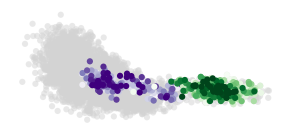

In [9]:
geo = 'rRNAModifications'
vlim = {'Pou5f1' : [0, 'p90'], 'Prrx1' : [1.25, 'p90']}
adata_plt = adata[adata.obs.source == geo].copy()

fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
sc.pl.embedding(adata, 'X_spectrum', size = 80, alpha = .5,
                frameon = False, show = False, ax = ax)
for g, (vmin, vmax) in vlim.items():
    sc.pl.embedding(adata_plt[adata_plt[:, g].X.toarray() > vmin],
                    'X_spectrum', size = 80, color = g,
                    cmap = cmap_dict[g], vmin = vmin,
                    vmax = vmax, colorbar_loc = None,
                    frameon = False, show = False, ax = ax)
ax.set_title('')
fn = os.path.join(pth_fig, f'{geo}.pdf')
plt.savefig(fn, bbox_inches = 'tight')